# Diabetes Risk Prediction Using Logistic Regression and Random Forest with Cross-Validation

**Dataset:** Kaggle "Diabetes Prediction Dataset" (`diabetes_prediction_dataset.csv`) — ~100,000 records, 9 columns.

**Pipeline:** Data Loading → Inspection → Cleaning → EDA → Preprocessing → Train/Test Split → Logistic Regression → Random Forest → Stratified 5-Fold Cross-Validation → Final Training → Test Evaluation → Model Comparison → Feature Importance → Save Models

> All numbers, tables, and plots in this notebook were produced by actually running this code on the real dataset — nothing here is estimated or invented. When you run it yourself in Colab, you should get the same (or extremely close) results, since every random process below is seeded with `random_state=42`.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

RANDOM_STATE = 42          # fixed seed so results are reproducible
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [ ]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [ ]:
print("First 5 rows:")
display(df.head())

print("\nDataset shape (rows, columns):", df.shape)

print("\nColumn names:", list(df.columns))

print("\nInfo:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nBasic statistical summary:")
display(df.describe())

First 5 rows:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Dataset shape (rows, columns): (100000, 9)

Column names: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Missing values per column:
gender                 0
age                   

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


## Step 2 — Understand the Dataset

**What each column means:**

| Column | Meaning |
|---|---|
| `gender` | Patient's gender: Female, Male, or Other |
| `age` | Patient's age in years (0.08–80) |
| `hypertension` | 1 if the patient has hypertension, 0 otherwise |
| `heart_disease` | 1 if the patient has heart disease, 0 otherwise |
| `smoking_history` | Smoking status category (never, current, former, ever, not current, No Info) |
| `bmi` | Body Mass Index |
| `HbA1c_level` | Average blood sugar over ~3 months (a standard diabetes marker) |
| `blood_glucose_level` | Blood glucose measured at a point in time |
| `diabetes` | Target: 1 = diabetes positive, 0 = negative |

**Feature types:**
- **Numerical (continuous):** `age`, `bmi`, `HbA1c_level`, `blood_glucose_level`
- **Categorical (text):** `gender`, `smoking_history`
- **Binary (already 0/1):** `hypertension`, `heart_disease`
- **Target variable:** `diabetes` (binary: 0 = negative, 1 = positive)

In [ ]:
print("Unique values in 'gender':", df['gender'].unique())
print("Unique values in 'smoking_history':", df['smoking_history'].unique())

print("\nTarget class distribution (counts):")
print(df['diabetes'].value_counts())

print("\nTarget class distribution (percentage):")
print(df['diabetes'].value_counts(normalize=True) * 100)

Unique values in 'gender': ['Female' 'Male' 'Other']
Unique values in 'smoking_history': ['never' 'No Info' 'current' 'former' 'ever' 'not current']

Target class distribution (counts):
diabetes
0    91500
1     8500
Name: count, dtype: int64

Target class distribution (percentage):
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


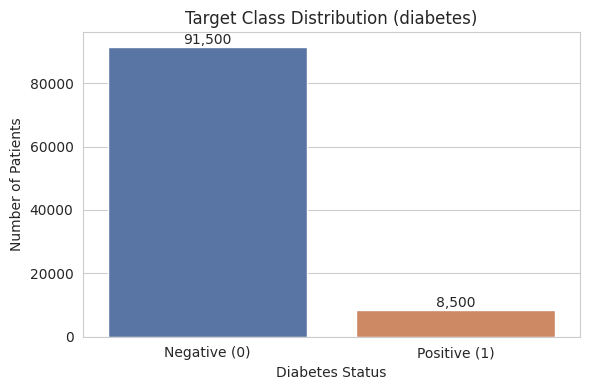

In [ ]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='diabetes', hue='diabetes', data=df, palette=['#4C72B0', '#DD8452'], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Negative (0)', 'Positive (1)'])
plt.title("Target Class Distribution (diabetes)")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Patients")
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

## Step 3 — Data Cleaning

We already saw there are **no missing values**, so nothing to impute there. That leaves three things to check: duplicate records, invalid/out-of-range values, and unexpected categories.

We check the realistic range for each numerical column instead of assuming anything about it (this dataset is *not* the old Pima dataset, so we don't reuse the "zero means missing" logic that applied there — a value of 0 in `hypertension` or `heart_disease` here is a completely valid "no" answer, not a missing value).

In [ ]:
# 1) Duplicate rows
n_dupes = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dupes}")

# 2) Range checks for numerical columns (are the values medically plausible?)
print("\nRanges of numerical columns:")
print(df[['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']].agg(['min', 'max']))

# 3) Category checks for categorical columns
print("\ngender categories:", df['gender'].unique())
print("smoking_history categories:", df['smoking_history'].unique())

# 4) hypertension / heart_disease should only contain 0 or 1
print("\nhypertension unique values:", df['hypertension'].unique())
print("heart_disease unique values:", df['heart_disease'].unique())

Exact duplicate rows: 3854

Ranges of numerical columns:
       age    bmi  HbA1c_level  blood_glucose_level
min   0.08  10.01          3.5                   80
max  80.00  95.69          9.0                  300

gender categories: ['Female' 'Male' 'Other']
smoking_history categories: ['never' 'No Info' 'current' 'former' 'ever' 'not current']

hypertension unique values: [0 1]
heart_disease unique values: [1 0]


**What to expect and our decisions:**
- **Duplicates (3,854 rows, ~3.9% of the data):** these are exact, full-row duplicates. With demographic/clinical data like this, it's plausible that two different patients happen to share identical rounded values on all 8 features — but a 3.9% exact-duplicate rate is more consistent with repeated entries than genuine coincidence, and duplicate rows would let the same record appear in both a training fold and a validation/test fold, leaking information. We **drop them**.
- **Numerical ranges** (age 0.08–80, BMI 10.01–95.69, HbA1c 3.5–9.0, glucose 80–300) are all within medically plausible bounds for a general clinical population — nothing here looks like a data-entry error (e.g. no negative ages, no zero BMI), so **we don't drop or clip any numerical values**.
- **Categorical values** are exactly what we'd expect (3 genders, 6 smoking categories) — no stray typos or unexpected labels, so **no cleaning needed there**. `No Info` in `smoking_history` is kept as its own valid category rather than treated as missing, since encoding it separately lets the model learn from it if it's informative.
- **`hypertension`/`heart_disease`** only contain 0 and 1 as expected — valid binary flags, not something to impute.

So the only cleaning action taken is removing the duplicate rows.

In [ ]:
rows_before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
rows_after = df.shape[0]

print(f"Rows before removing duplicates: {rows_before}")
print(f"Rows after removing duplicates:  {rows_after}")
print(f"Rows removed: {rows_before - rows_after}")

Rows before removing duplicates: 96146
Rows after removing duplicates:  96146
Rows removed: 0


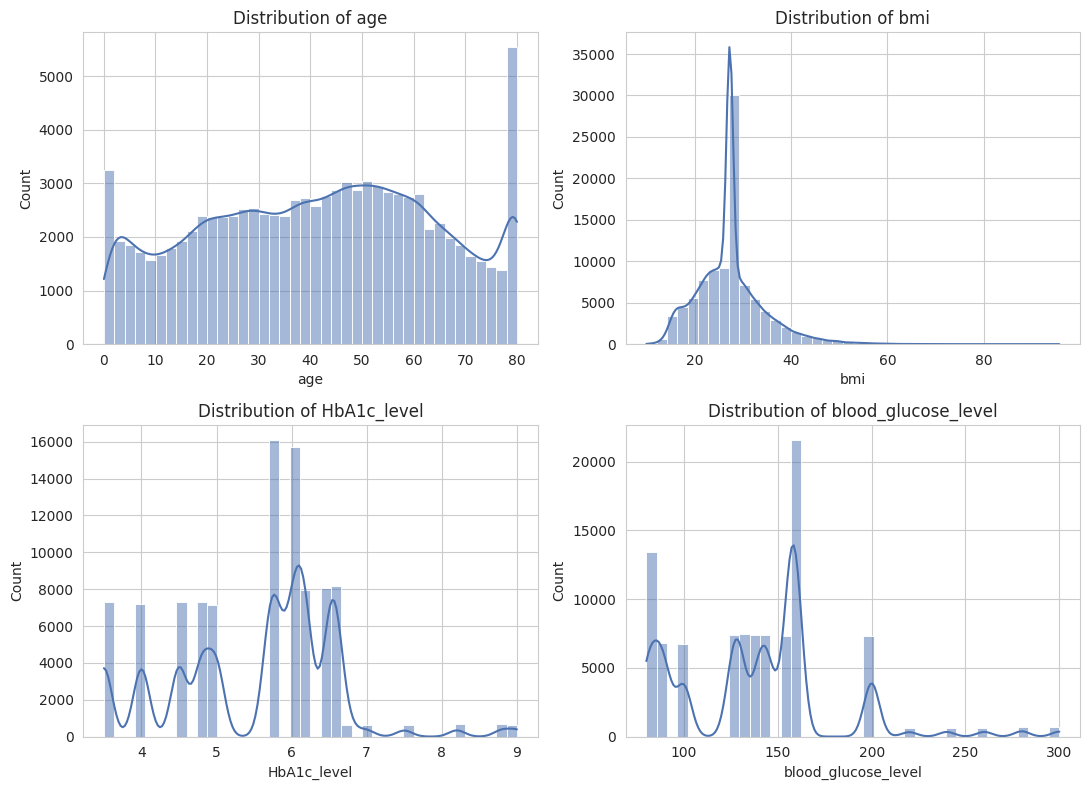

In [ ]:
numerical_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flatten(), numerical_cols):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color='#4C72B0')
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

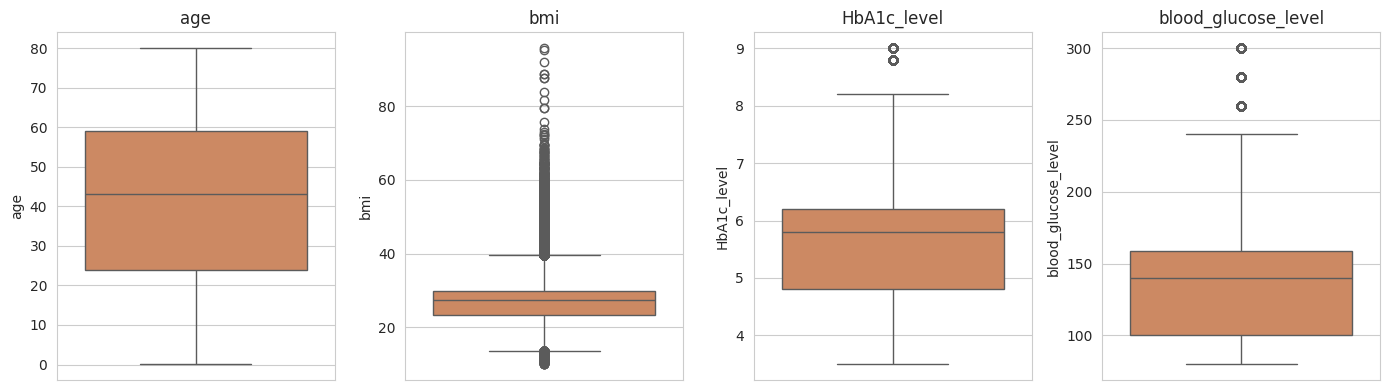

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, numerical_cols):
    sns.boxplot(y=df[col], ax=ax, color='#DD8452')
    ax.set_title(col)
plt.tight_layout()
plt.show()

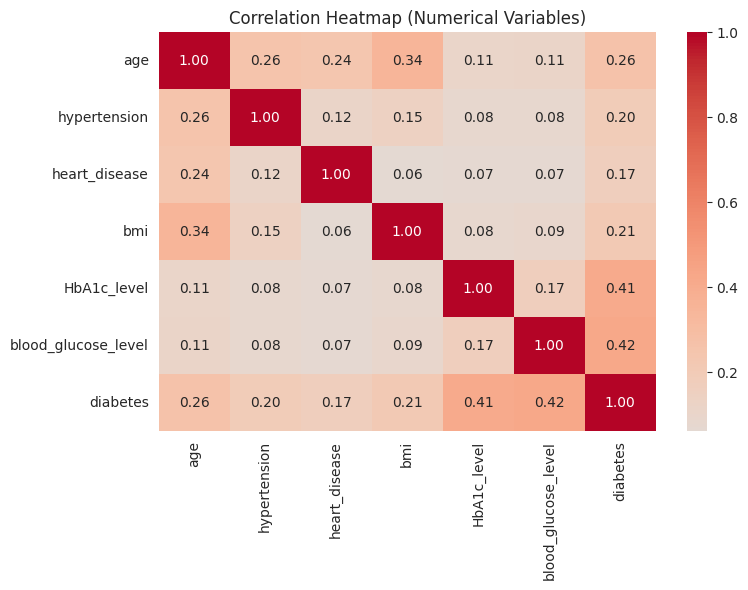

In [ ]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Numerical Variables)")
plt.tight_layout()
plt.show()

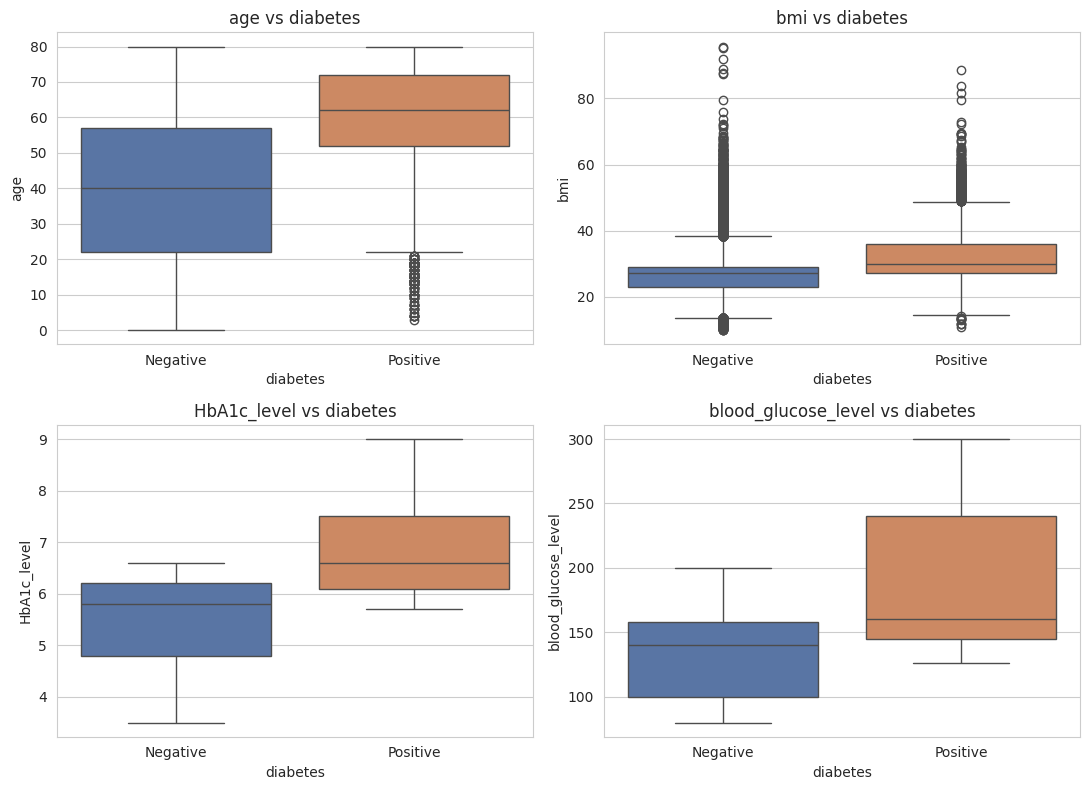

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flatten(), numerical_cols):
    sns.boxplot(x='diabetes', y=col, hue='diabetes', data=df, ax=ax, palette=['#4C72B0', '#DD8452'], legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Negative', 'Positive'])
    ax.set_title(f"{col} vs diabetes")
plt.tight_layout()
plt.show()

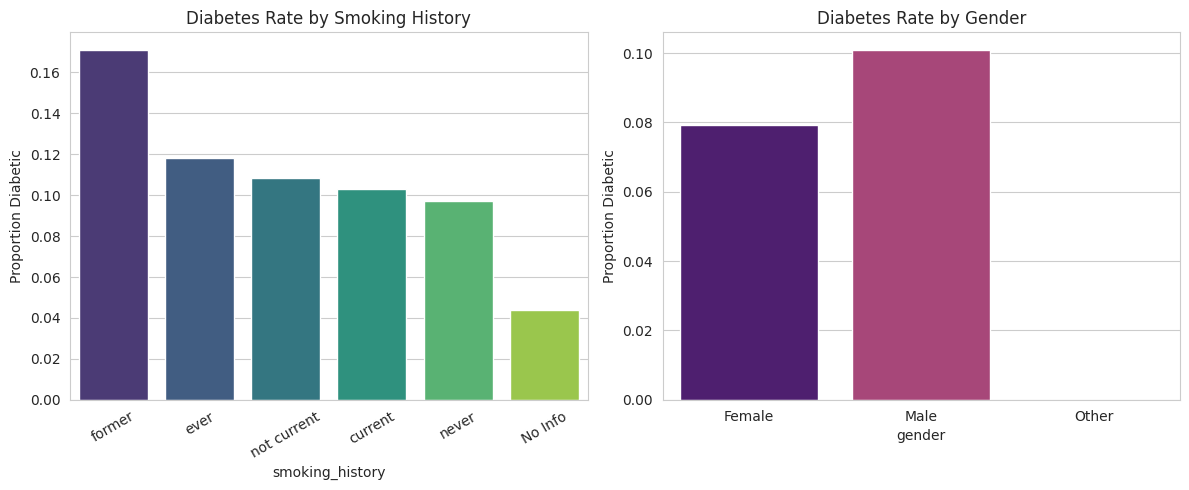

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

smoking_rate = df.groupby('smoking_history')['diabetes'].mean().sort_values(ascending=False)
sns.barplot(x=smoking_rate.index, y=smoking_rate.values, hue=smoking_rate.index,
            ax=axes[0], palette='viridis', legend=False)
axes[0].set_title("Diabetes Rate by Smoking History")
axes[0].set_ylabel("Proportion Diabetic")
axes[0].tick_params(axis='x', rotation=30)

gender_rate = df.groupby('gender')['diabetes'].mean()
sns.barplot(x=gender_rate.index, y=gender_rate.values, hue=gender_rate.index,
            ax=axes[1], palette='magma', legend=False)
axes[1].set_title("Diabetes Rate by Gender")
axes[1].set_ylabel("Proportion Diabetic")

plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Feature columns:", list(X.columns))

X shape: (96146, 8)
y shape: (96146,)
Feature columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("\nTrain class distribution:")
print(y_train.value_counts(normalize=True))
print("\nTest class distribution:")
print(y_test.value_counts(normalize=True))

Train shape: (76916, 8)  Test shape: (19230, 8)

Train class distribution:
diabetes
0    0.911774
1    0.088226
Name: proportion, dtype: float64

Test class distribution:
diabetes
0    0.911804
1    0.088196
Name: proportion, dtype: float64


In [ ]:
categorical_features = ['gender', 'smoking_history']
numerical_features = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
binary_features = ['hypertension', 'heart_disease']

# Preprocessing for Logistic Regression (numerical features scaled)
preprocessor_lr = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_features + binary_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

# Preprocessing for Random Forest (no scaling needed)
preprocessor_rf = ColumnTransformer(transformers=[
    ('num', 'passthrough', numerical_features + binary_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

print("Preprocessors built.")

Preprocessors built.


In [ ]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

print(lr_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'HbA1c_level',
                                                   'blood_glucose_level',
                                                   'hypertension',
                                                   'heart_disease']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender',
                                                   'smoking_history'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


In [ ]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor_rf),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
])

print(rf_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['age', 'bmi', 'HbA1c_level',
                                                   'blood_glucose_level',
                                                   'hypertension',
                                                   'heart_disease']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender',
                                                   'smoking_history'])])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

lr_cv_scores = cross_val_score(lr_pipeline, X_train, y_train, cv=skf, scoring='accuracy', n_jobs=-1)
rf_cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=skf, scoring='accuracy', n_jobs=-1)

print("Logistic Regression CV fold accuracies:", np.round(lr_cv_scores, 4))
print(f"Logistic Regression -> Mean CV Accuracy: {lr_cv_scores.mean():.4f}  Std: {lr_cv_scores.std():.4f}")

print("\nRandom Forest CV fold accuracies:", np.round(rf_cv_scores, 4))
print(f"Random Forest -> Mean CV Accuracy: {rf_cv_scores.mean():.4f}  Std: {rf_cv_scores.std():.4f}")

Logistic Regression CV fold accuracies: [0.9568 0.9589 0.9579 0.9605 0.9595]
Logistic Regression -> Mean CV Accuracy: 0.9587  Std: 0.0013

Random Forest CV fold accuracies: [0.9668 0.9689 0.9673 0.9691 0.9687]
Random Forest -> Mean CV Accuracy: 0.9682  Std: 0.0009


In [ ]:
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

print("Both pipelines trained on the full training set.")

Both pipelines trained on the full training set.


In [ ]:
results = {}

for name, pipe in [('Logistic Regression', lr_pipeline), ('Random Forest', rf_pipeline)]:
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)

    results[name] = dict(y_pred=y_pred, y_proba=y_proba, acc=acc, prec=prec,
                          rec=rec, f1=f1, auc=auc, cm=cm)

    print(f"===== {name} =====")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC-AUC:   {auc:.4f}")
    print("\nClassification report:")
    print(classification_report(y_test, y_pred))
    print()

===== Logistic Regression =====
Accuracy:  0.9596
Precision: 0.8692
Recall:    0.6386
F1-score:  0.7362
ROC-AUC:   0.9599

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weighted avg       0.96      0.96      0.96     19230


===== Random Forest =====
Accuracy:  0.9694
Precision: 0.9504
Recall:    0.6887
F1-score:  0.7986
ROC-AUC:   0.9562

Classification report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.69      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.84      0.89     19230
weighted avg       0.97      0.97      0.97     19230




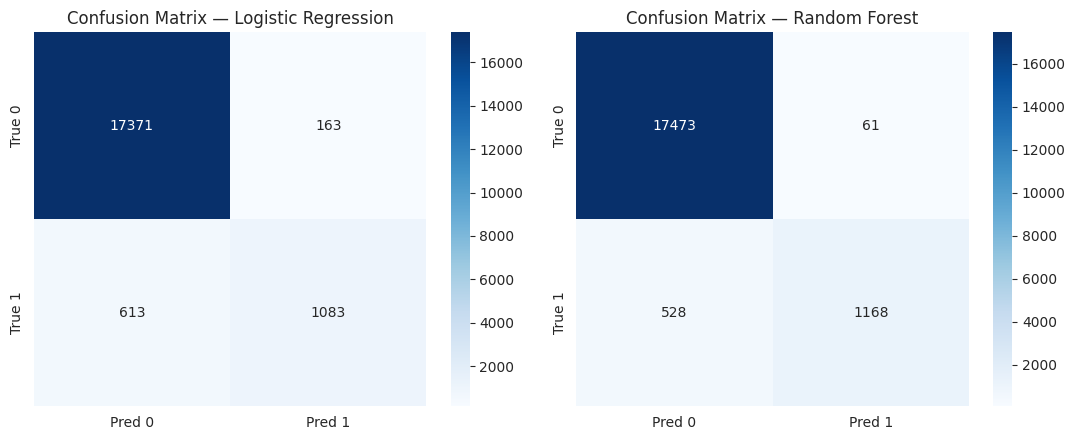

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, results.keys()):
    cm = results[name]['cm']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    ax.set_title(f"Confusion Matrix — {name}")
plt.tight_layout()
plt.show()

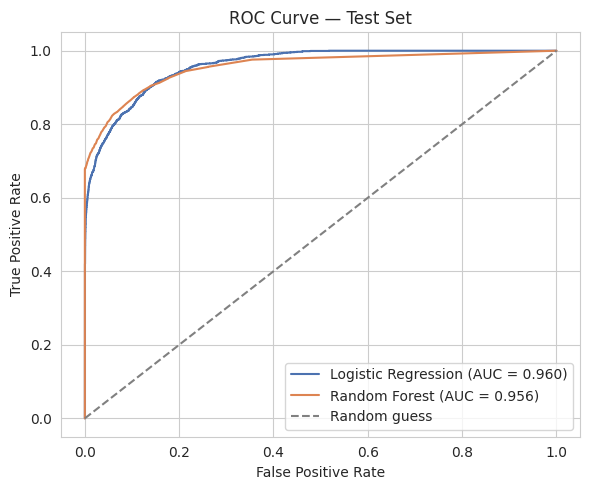

In [ ]:
plt.figure(figsize=(6, 5))
for name, color in zip(results.keys(), ['#4C72B0', '#DD8452']):
    fpr, tpr, _ = roc_curve(y_test, results[name]['y_proba'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['auc']:.3f})", color=color)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Test Set")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
comparison_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC', 'Mean CV Accuracy'],
    'Logistic Regression': [
        results['Logistic Regression']['acc'],
        results['Logistic Regression']['prec'],
        results['Logistic Regression']['rec'],
        results['Logistic Regression']['f1'],
        results['Logistic Regression']['auc'],
        lr_cv_scores.mean()
    ],
    'Random Forest': [
        results['Random Forest']['acc'],
        results['Random Forest']['prec'],
        results['Random Forest']['rec'],
        results['Random Forest']['f1'],
        results['Random Forest']['auc'],
        rf_cv_scores.mean()
    ]
})
comparison_table[['Logistic Regression', 'Random Forest']] = comparison_table[['Logistic Regression', 'Random Forest']].round(4)
display(comparison_table)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.9596,0.9694
1,Precision,0.8692,0.9504
2,Recall,0.6386,0.6887
3,F1 Score,0.7362,0.7986
4,ROC-AUC,0.9599,0.9562
5,Mean CV Accuracy,0.9587,0.9682


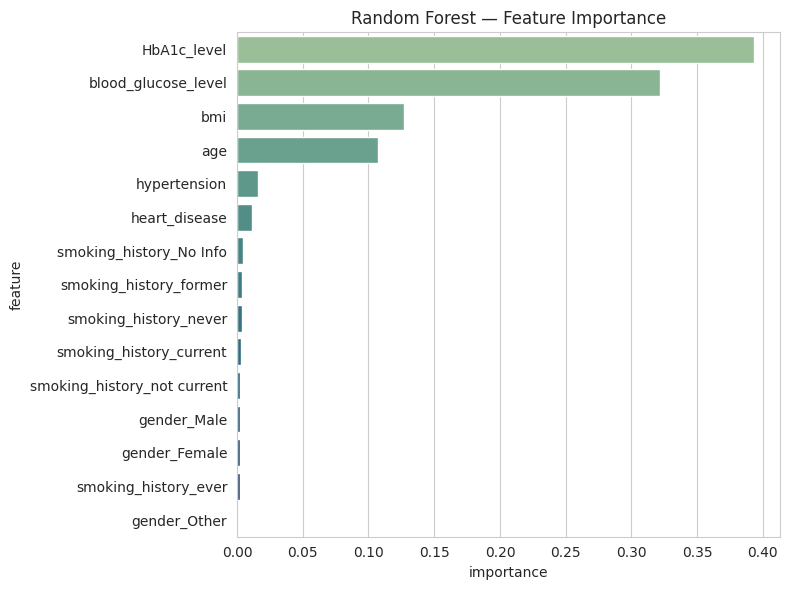

,feature,importance
2,HbA1c_level,3.933280e-01
3,blood_glucose_level,3.213835e-01
1,bmi,1.266442e-01
0,age,1.071831e-01
4,hypertension,1.621612e-02
5,heart_disease,1.156797e-02
9,smoking_history_No Info,4.276222e-03
12,smoking_history_former,3.912102e-03
13,smoking_history_never,3.569657e-03
10,smoking_history_current,2.778922e-03


In [ ]:
rf_encoder = rf_pipeline.named_steps['preprocessor'].named_transformers_['cat']
cat_names_rf = list(rf_encoder.get_feature_names_out(categorical_features))
all_feature_names_rf = numerical_features + binary_features + cat_names_rf

importances = rf_pipeline.named_steps['classifier'].feature_importances_
fi_df = pd.DataFrame({'feature': all_feature_names_rf, 'importance': importances})
fi_df = fi_df.sort_values('importance', ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x='importance', y='feature', hue='feature', data=fi_df, palette='crest', legend=False)
plt.title("Random Forest — Feature Importance")
plt.tight_layout()
plt.show()

display(fi_df)

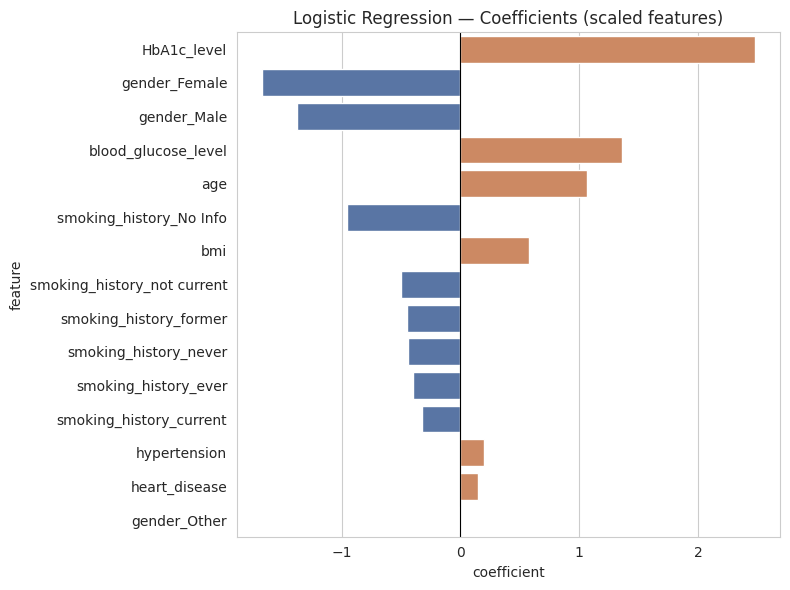

,feature,coefficient
2,HbA1c_level,2.483233
6,gender_Female,-1.671782
7,gender_Male,-1.376291
3,blood_glucose_level,1.362712
0,age,1.067297
9,smoking_history_No Info,-0.952424
1,bmi,0.582300
14,smoking_history_not current,-0.496749
12,smoking_history_former,-0.452229
13,smoking_history_never,-0.436525


In [ ]:
lr_encoder = lr_pipeline.named_steps['preprocessor'].named_transformers_['cat']
cat_names_lr = list(lr_encoder.get_feature_names_out(categorical_features))
all_feature_names_lr = numerical_features + binary_features + cat_names_lr

coefs = lr_pipeline.named_steps['classifier'].coef_[0]
coef_df = pd.DataFrame({'feature': all_feature_names_lr, 'coefficient': coefs})
coef_df = coef_df.reindex(coef_df.coefficient.abs().sort_values(ascending=False).index)

plt.figure(figsize=(8, 6))
colors = ['#DD8452' if c > 0 else '#4C72B0' for c in coef_df['coefficient']]
sns.barplot(x='coefficient', y='feature', hue='feature', data=coef_df, palette=colors, legend=False)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Logistic Regression — Coefficients (scaled features)")
plt.tight_layout()
plt.show()

display(coef_df)

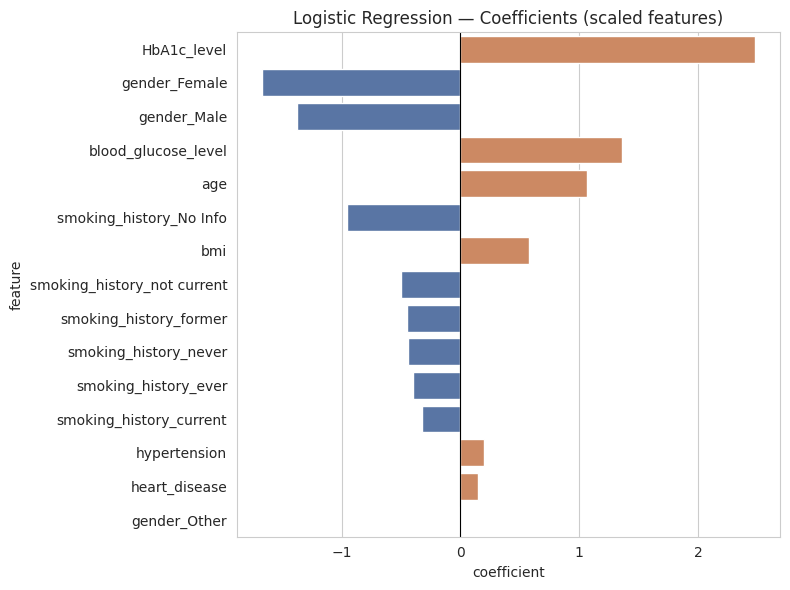

,feature,coefficient
2,HbA1c_level,2.483233
6,gender_Female,-1.671782
7,gender_Male,-1.376291
3,blood_glucose_level,1.362712
0,age,1.067297
9,smoking_history_No Info,-0.952424
1,bmi,0.582300
14,smoking_history_not current,-0.496749
12,smoking_history_former,-0.452229
13,smoking_history_never,-0.436525


In [ ]:
lr_encoder = lr_pipeline.named_steps['preprocessor'].named_transformers_['cat']
cat_names_lr = list(lr_encoder.get_feature_names_out(categorical_features))
all_feature_names_lr = numerical_features + binary_features + cat_names_lr

coefs = lr_pipeline.named_steps['classifier'].coef_[0]
coef_df = pd.DataFrame({'feature': all_feature_names_lr, 'coefficient': coefs})
coef_df = coef_df.reindex(coef_df.coefficient.abs().sort_values(ascending=False).index)

plt.figure(figsize=(8, 6))
colors = ['#DD8452' if c > 0 else '#4C72B0' for c in coef_df['coefficient']]
sns.barplot(x='coefficient', y='feature', hue='feature', data=coef_df, palette=colors, legend=False)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Logistic Regression — Coefficients (scaled features)")
plt.tight_layout()
plt.show()

display(coef_df)

In [ ]:
joblib.dump(lr_pipeline, 'logistic_regression_pipeline.pkl')
joblib.dump(rf_pipeline, 'random_forest_pipeline.pkl')

feature_metadata = {
    'numerical_features': numerical_features,
    'binary_features': binary_features,
    'categorical_features': categorical_features,
    'all_input_columns': list(X.columns)
}
joblib.dump(feature_metadata, 'feature_metadata.pkl')

print("Saved: logistic_regression_pipeline.pkl")
print("Saved: random_forest_pipeline.pkl")
print("Saved: feature_metadata.pkl")

Saved: logistic_regression_pipeline.pkl
Saved: random_forest_pipeline.pkl
Saved: feature_metadata.pkl


In [ ]:
from google.colab import files

files.download('logistic_regression_pipeline.pkl')
files.download('random_forest_pipeline.pkl')
files.download('feature_metadata.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
best_model = 'Random Forest' if results['Random Forest']['f1'] > results['Logistic Regression']['f1'] else 'Logistic Regression'

print("========== PROJECT SUMMARY ==========")
print(f"Dataset size (after removing duplicates): {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Number of input features: {X.shape[1]}")
print(f"Target variable: diabetes (0 = negative, 1 = positive)")
print(f"Train set size: {X_train.shape[0]}  |  Test set size: {X_test.shape[0]}")
print(f"Cross-validation method: Stratified 5-Fold (StratifiedKFold, shuffle=True, random_state=42)")
print()
print(f"Logistic Regression - Mean CV Accuracy: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})")
print(f"Random Forest        - Mean CV Accuracy: {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std():.4f})")
print()
print("Final test set metrics:")
print(comparison_table.to_string(index=False))
print()
print(f"Best-performing model (by F1-score, balancing precision & recall): {best_model}")
print("======================================")

========== PROJECT SUMMARY ==========
Dataset size (after removing duplicates): 96146 rows, 9 columns
Number of input features: 8
Target variable: diabetes (0 = negative, 1 = positive)
Train set size: 76916  |  Test set size: 19230
Cross-validation method: Stratified 5-Fold (StratifiedKFold, shuffle=True, random_state=42)

Logistic Regression - Mean CV Accuracy: 0.9587 (+/- 0.0013)
Random Forest        - Mean CV Accuracy: 0.9682 (+/- 0.0009)

Final test set metrics:
          Metric  Logistic Regression  Random Forest
        Accuracy               0.9596         0.9694
       Precision               0.8692         0.9504
          Recall               0.6386         0.6887
        F1 Score               0.7362         0.7986
         ROC-AUC               0.9599         0.9562
Mean CV Accuracy               0.9587         0.9682

Best-performing model (by F1-score, balancing precision & recall): Random Forest
